<a href="https://colab.research.google.com/github/epro-tech-create/COU07506-labs/blob/main/COU07506_Week04_240242421899.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


 COU 07506 Digital Signal Processing
 Week 04 – Lab 1B
 Convolution, Correlation and Difference Equations

Name:Gasper Denis Mwansisya
Registration Number:240242421899
Class:BENG24COE


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams["figure.figsize"] = (9, 3.5)

Task 4.1 — A pole-zero plotting function

In [2]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)

    ax = ax or plt.gca()

    th = np.linspace(0, 2*np.pi, 400)

    # Draw the unit circle
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)

    # Plot zeros as circles
    ax.plot(z.real, z.imag, "o",
            mfc="none", ms=9, label="zeros")

    # Plot poles as crosses
    ax.plot(p.real, p.imag, "x",
            ms=9, mew=2, label="poles")

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")

    return z, p

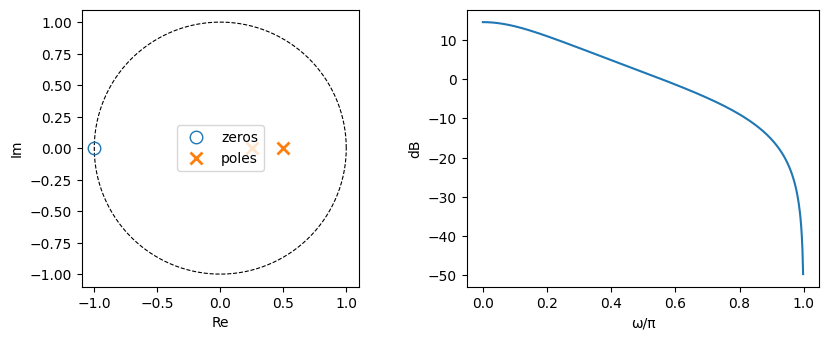

zeros: [-1.]
poles: [0.5  0.25]
stable: True


In [3]:
b, a = [1, 1], [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 3.6)
)

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)

ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("dB")

plt.show()

print("zeros:", z)
print("poles:", p)
print("stable:", np.all(np.abs(p) < 1))

Task 4.2 — Inverse z-transform with residuez

In [4]:
r, p, k = signal.residuez(
    [1], [1, -0.75, 0.125]
)

print("residues", r, "poles", p)

n = np.arange(10)

x_pf = sum(
    ri * pi**n for ri, pi in zip(r, p)
).real

impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter(
    [1], [1, -0.75, 0.125], impulse
)

print(np.allclose(x_pf, x_lf))

residues [-1.  2.] poles [0.25 0.5 ]
True


In [5]:
r, p, k = signal.residuez(
    [1, 1], [1, -0.75, 0.125]
)

print("residues:", r)
print("poles:", p)

residues: [-5.  6.]
poles: [0.25 0.5 ]


Task 4.3 — Pole position and the impulse response

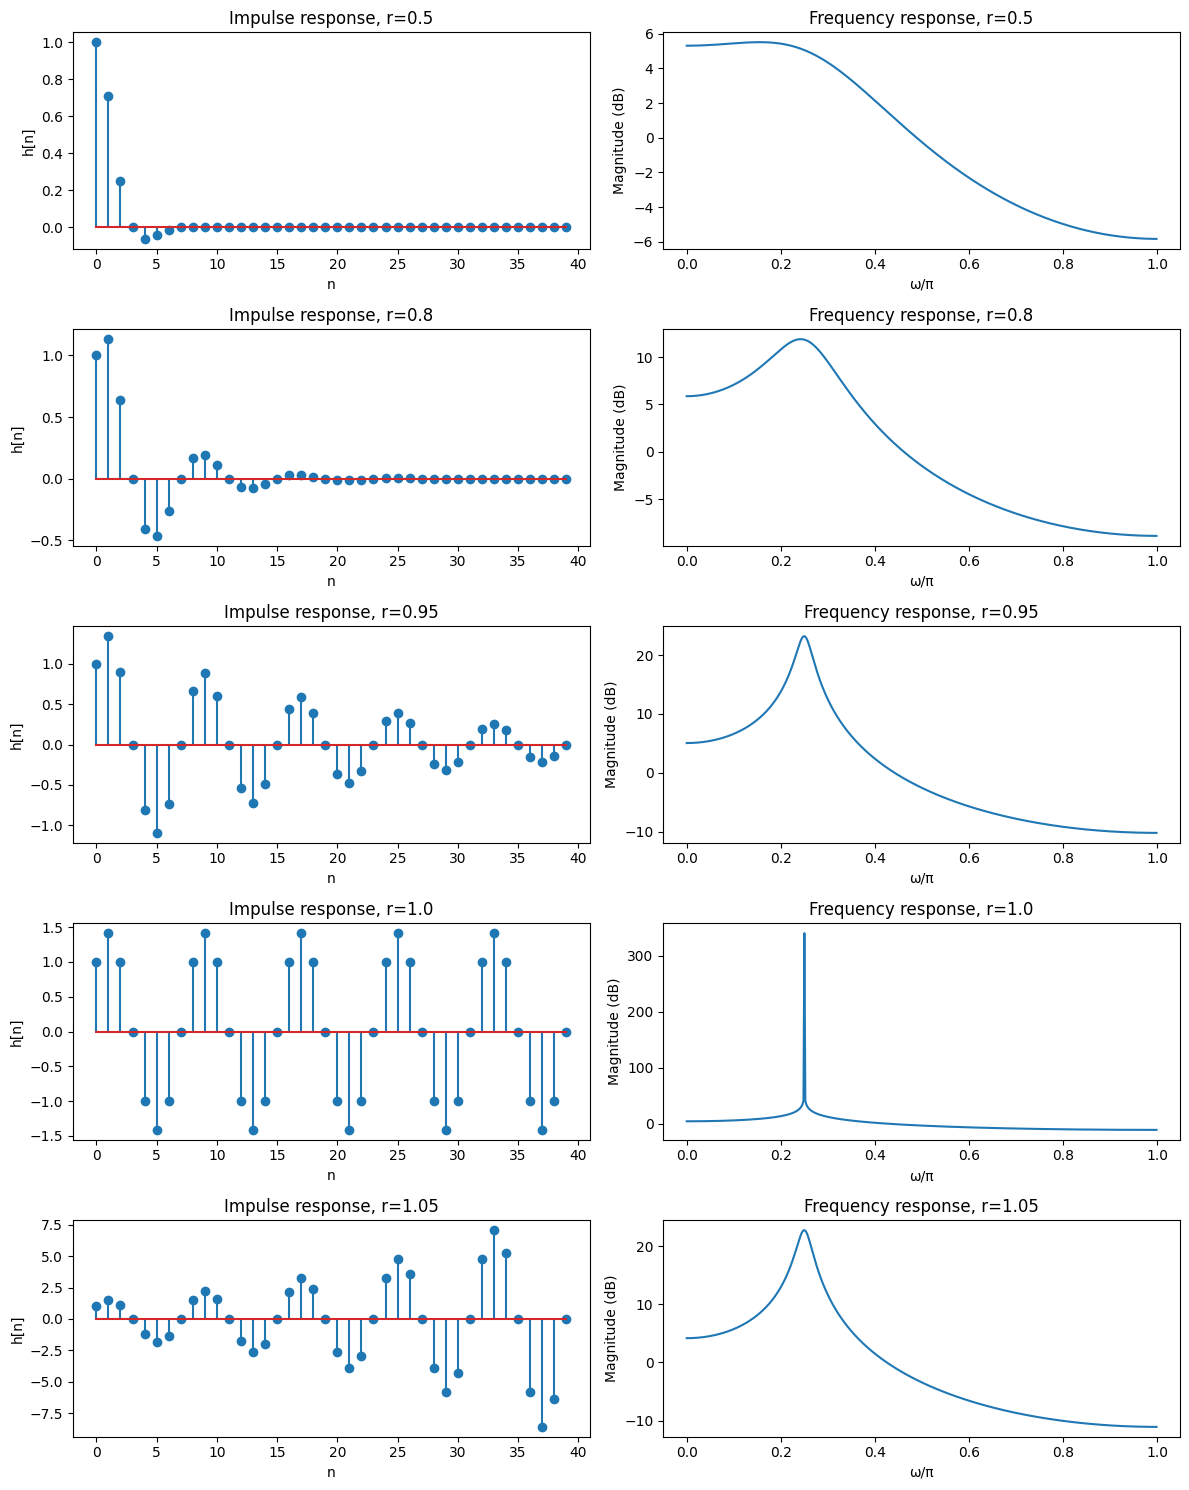

In [6]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1

fig, axes = plt.subplots(
    len(r_values), 2,
    figsize=(12, 15)
)

for i, r in enumerate(r_values):

    a = [
        1,
        -2*r*np.cos(np.pi/4),
        r**2
    ]

    # Impulse response
    h = signal.lfilter([1], a, impulse)

    # Frequency response
    w, H = signal.freqz([1], a, worN=512)

    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(f"Impulse response, r={r}")
    axes[i, 0].set_xlabel("n")
    axes[i, 0].set_ylabel("h[n]")

    axes[i, 1].plot(w/np.pi, 20*np.log10(
        np.maximum(np.abs(H), 1e-10)
    ))
    axes[i, 1].set_title(f"Frequency response, r={r}")
    axes[i, 1].set_xlabel("ω/π")
    axes[i, 1].set_ylabel("Magnitude (dB)")

plt.tight_layout()
plt.show()

Task 4.4 — Stability of given systems

H1:
Poles: [0.8+0.5j 0.8-0.5j]
Stable: True

H2:
Poles: [2.  0.5]
Stable: False

H3:
Poles: [-1.   0.5]
Stable: False

H4:
Poles: []
Stable: True



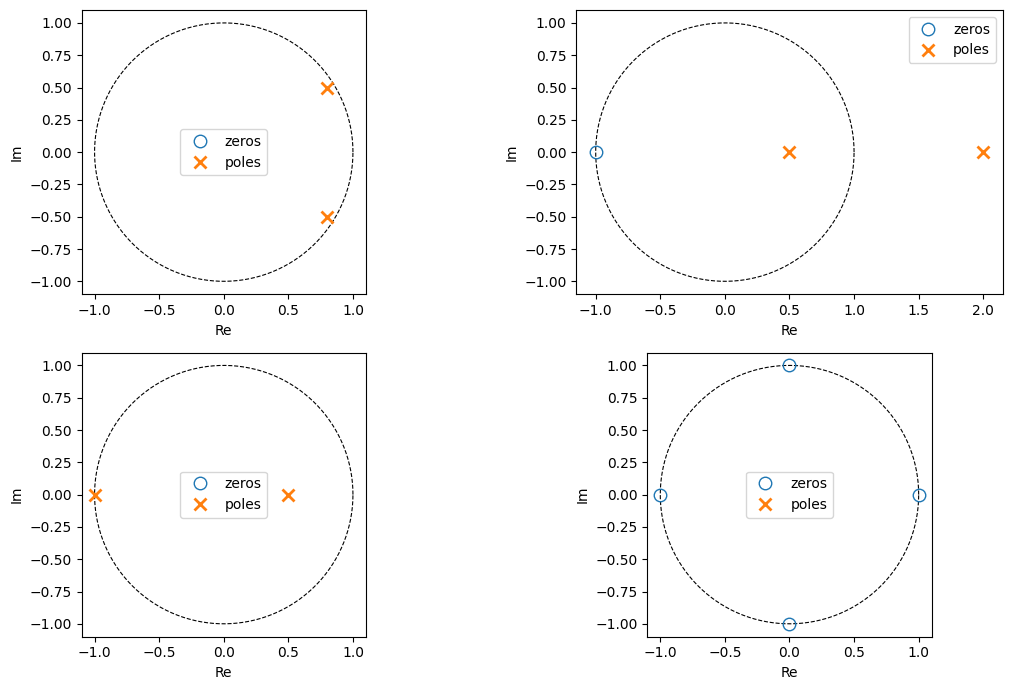

In [7]:
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

impulse = np.zeros(50)
impulse[0] = 1

fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, (name, (b, a)) in zip(axes.flat, systems.items()):

    z, p = zplane(b, a, ax)

    h = signal.lfilter(b, a, impulse)

    stable = np.all(np.abs(p) < 1)

    print(f"{name}:")
    print("Poles:", p)
    print("Stable:", stable)
    print()

plt.tight_layout()
plt.show()

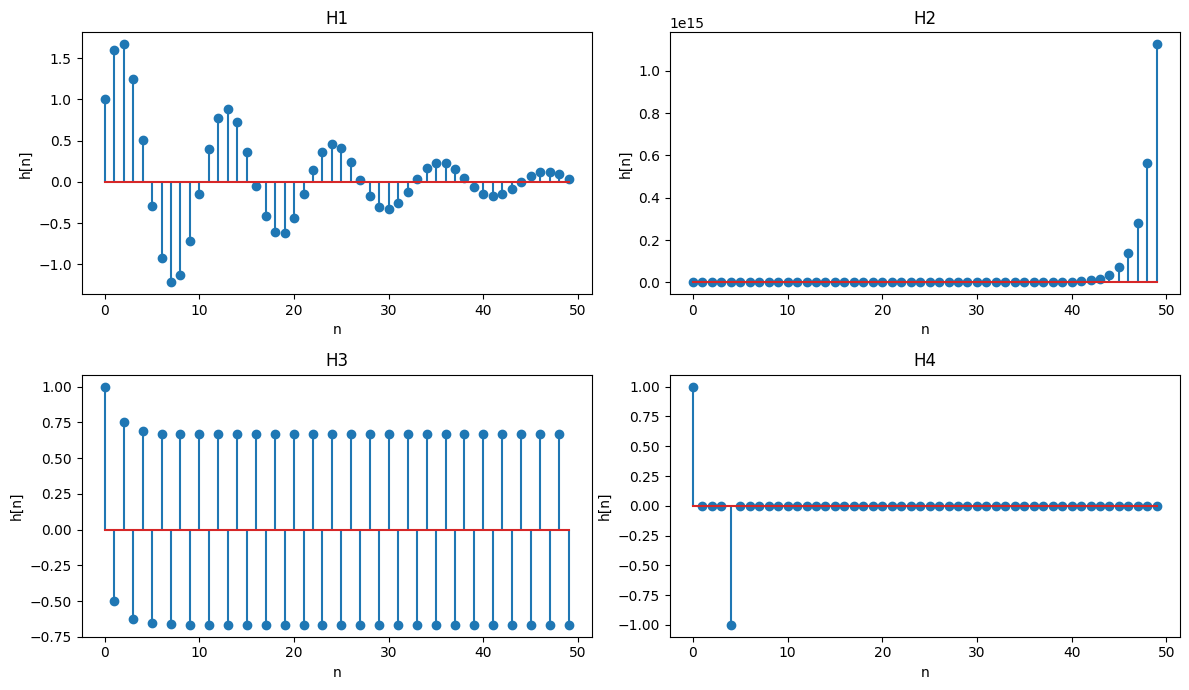

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, (name, (b, a)) in zip(axes.flat, systems.items()):

    h = signal.lfilter(b, a, impulse)

    ax.stem(np.arange(len(h)), h)
    ax.set_title(name)
    ax.set_xlabel("n")
    ax.set_ylabel("h[n]")

plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio, display

# Design specifications
fs = 8000
f0 = 1000
r = 0.97

# Calculate digital angular frequency
w0 = 2 * np.pi * f0 / fs

# Numerator: zeros at +1 and -1
b = [1, 0, -1]

# Denominator: poles at radius r and angle ±w0
a = [
    1,
    -2 * r * np.cos(w0),
    r**2
]

print("Numerator:", b)
print("Denominator:", a)
print("Pole angle:", w0)

Numerator: [1, 0, -1]
Denominator: [1, np.float64(-1.3717871555019023), 0.9409]
Pole angle: 0.7853981633974483


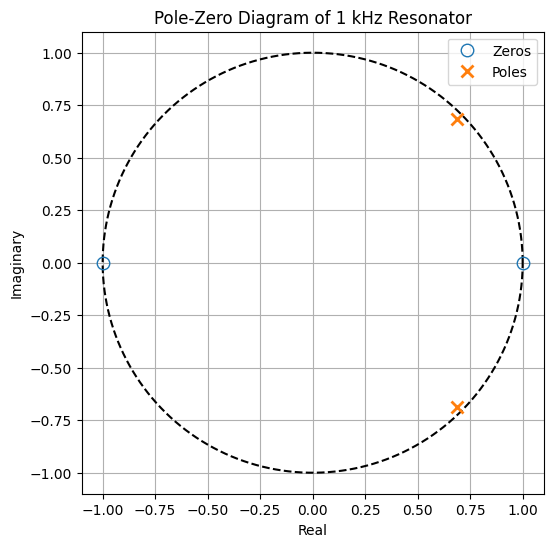

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Stable: True


In [10]:
def zplane(b, a, ax=None):

    z, p, k = signal.tf2zpk(b, a)

    ax = ax or plt.gca()

    th = np.linspace(0, 2*np.pi, 400)

    # Unit circle
    ax.plot(np.cos(th), np.sin(th), "k--")

    # Zeros
    ax.plot(
        z.real, z.imag,
        "o", mfc="none", ms=9, label="Zeros"
    )

    # Poles
    ax.plot(
        p.real, p.imag,
        "x", ms=9, mew=2, label="Poles"
    )

    ax.set_aspect("equal")
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")
    ax.legend()
    ax.grid(True)

    return z, p


fig, ax = plt.subplots(figsize=(6, 6))

z, p = zplane(b, a, ax)

plt.title("Pole-Zero Diagram of 1 kHz Resonator")
plt.show()

print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

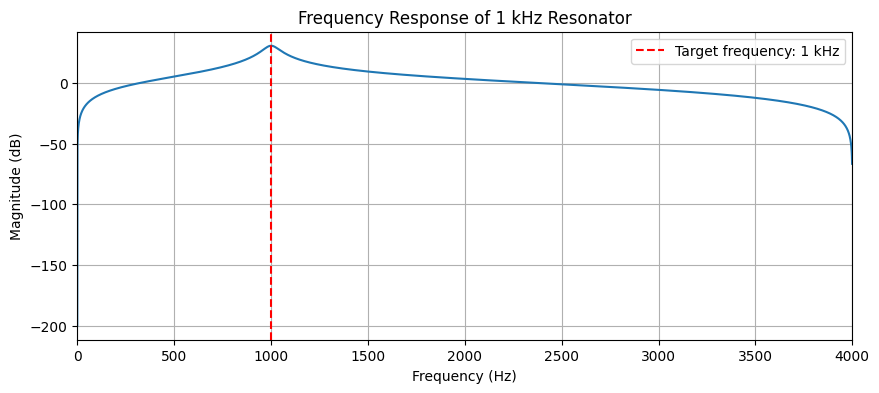

Peak frequency: 1000.9765625 Hz
Peak magnitude: 30.5884192923415 dB


In [11]:
w, H = signal.freqz(b, a, worN=4096, fs=fs)

magnitude_db = 20 * np.log10(
    np.maximum(np.abs(H), 1e-10)
)

plt.figure(figsize=(10, 4))

plt.plot(w, magnitude_db)

plt.title("Frequency Response of 1 kHz Resonator")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")

plt.axvline(
    f0, color="red", linestyle="--",
    label="Target frequency: 1 kHz"
)

plt.xlim(0, fs/2)
plt.grid(True)
plt.legend()
plt.show()

peak_index = np.argmax(np.abs(H))

print("Peak frequency:", w[peak_index], "Hz")
print("Peak magnitude:", magnitude_db[peak_index], "dB")

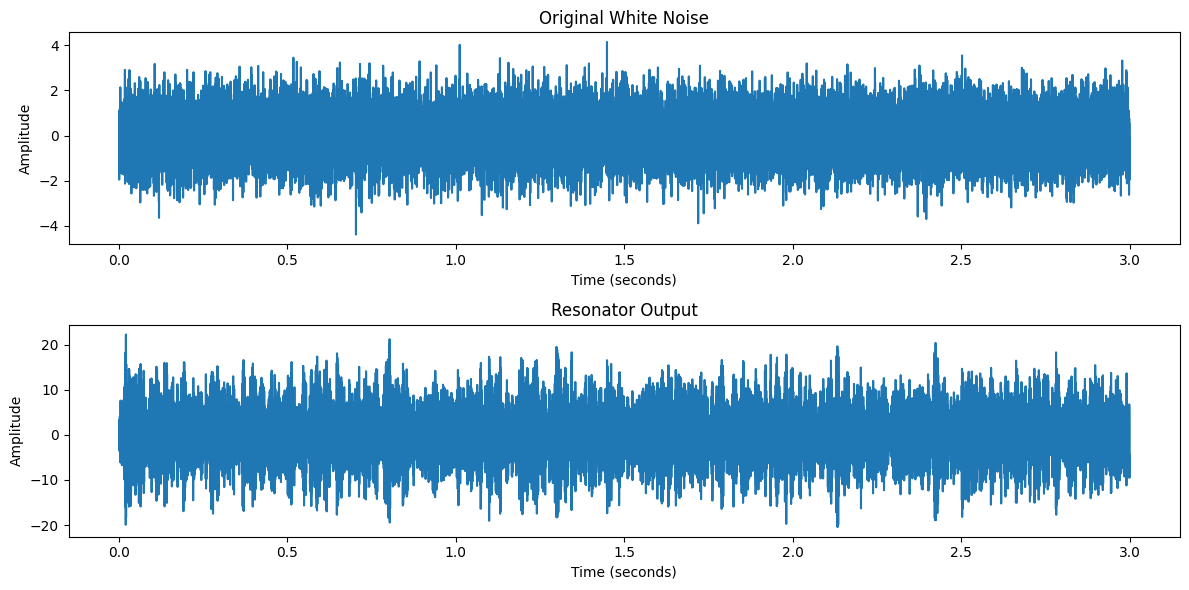

In [12]:
# Generate white noise
rng = np.random.default_rng(42)

duration = 3  # seconds
N = fs * duration

x = rng.standard_normal(N)

# Apply the resonator
y = signal.lfilter(b, a, x)

# Plot input and output
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(np.arange(N)/fs, x)
axes[0].set_title("Original White Noise")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")

axes[1].plot(np.arange(N)/fs, y)
axes[1].set_title("Resonator Output")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

### AI-Use Statement

**AI tools used:** ChatGPT (OpenAI).

**Used for:** Understanding z-transform concepts, identifying poles and zeros, explaining system stability, solving the pre-lab questions, and assisting with Python code for Tasks 4.1–4.4.

**How I verified the output:** I ran the Python code in Google Colab, checked the calculated poles and zeros using SciPy, compared the inverse z-transform results from `residuez` with `lfilter`, and examined the impulse and frequency response plots to verify system stability.

All submitted code and results have been reviewed
and understood by me.